In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")              # project root (guarded, so re-running the cell is safe)
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
from train import load_splits, build_pipeline 
%matplotlib inline
from models.model_utils import predict_with_threshold

train_df, val_df, _, _, _ = load_splits("datasets/sample1.csv", "datasets/cache")
pipe = build_pipeline("logreg", 100000, 2).fit(train_df["processed_text"], train_df["issue_label"])

T = 0.50  # question threshold chosen by train.py --tune-threshold (see MLflow param question_threshold)
P = pipe.predict_proba(val_df["processed_text"])
val = val_df.copy()
val["pred"] = predict_with_threshold(P, pipe.classes_, T)
for i, label in enumerate(pipe.classes_):
    val[f"p_{label}"] = P[:, i]
errors = val[val["pred"] != val["issue_label"]]

def show(rows, n_chars=400):
    """Print issues with their index, labels and probabilities. Raise n_chars to read whole bodies."""
    for idx, r in rows.iterrows():
        body = " ".join(str(r.issue_body).split())[:n_chars]   # collapses \r, \n, tabs and repeated spaces
        print(f"[{idx}] TRUE {r.issue_label} | PRED {r.pred} | "
              f"bug {r.p_bug:.2f} enh {r.p_enhancement:.2f} q {r.p_question:.2f}")
        print("TITLE:", r.issue_title)
        print("BODY: ", body)
        print("-" * 80)

/Users/ervinballa/Desktop/Ticket-Classifier/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using cached preprocessed text from datasets/cache/processed_96e5c4fc_92d30e8a.pkl
Removed 332 issues with conflicting labels and 1326 duplicates, 70631 left
Language/empty filter removed 5783 issues


**Q1: Where are the errors?** Which mistake is most common in absolute numbers, and which is worst relative to class size?

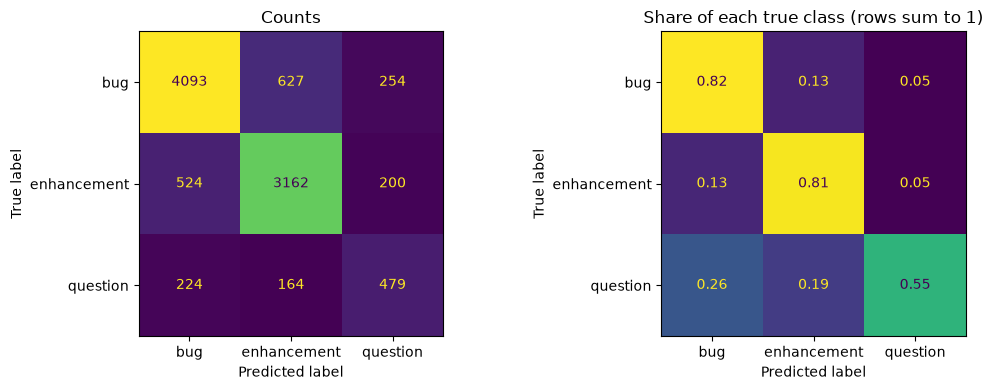

              precision    recall  f1-score   support

         bug      0.845     0.823     0.834      4974
 enhancement      0.800     0.814     0.807      3886
    question      0.513     0.552     0.532       867

    accuracy                          0.795      9727
   macro avg      0.720     0.730     0.724      9727
weighted avg      0.798     0.795     0.796      9727



In [2]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

LABELS = ["bug", "enhancement", "question"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left: absolute counts — "how many issues does each mistake affect?"
ConfusionMatrixDisplay.from_predictions(
    val["issue_label"], val["pred"], labels=LABELS, ax=axes[0], colorbar=False)
axes[0].set_title("Counts")

# Right: normalized per row — "what share of each TRUE class ends up where?"
ConfusionMatrixDisplay.from_predictions(
    val["issue_label"], val["pred"], labels=LABELS, normalize="true",
    values_format=".2f", ax=axes[1], colorbar=False)
axes[1].set_title("Share of each true class (rows sum to 1)")

plt.tight_layout()
plt.show()

print(classification_report(val["issue_label"], val["pred"], digits=3))

**Answer:**
- **Most common in absolute numbers:** bugs predicted as enhancement (627). Bug and enhancement are the two large classes, so even a small share of confusion between them affects many issues.
- **Worst relative to class size:** questions. 26% of real questions are predicted as bug and 19% as enhancement, so almost half are missed (recall 0.55). In the other direction, about half of the predicted questions are wrong (precision 0.51).
- Overall: 1,993 of 9,727 validation issues (20.5%) are misclassified; macro-F1 0.724.

**Q2: Confident mistakes.** Errors where the model was very sure (max probability ≥ 0.9). Read 20 and sort each one into a category:
- **label noise**: the model is actually right and the label is wrong
- **ambiguous**: both labels are defensible
- **model error**: the label is clearly right and the model missed it

Rule used for all verdicts: *what would a neutral reader choose from title + body?*

In [3]:
confident_mistakes = errors[errors[["p_bug", "p_enhancement", "p_question"]].max(axis=1) >= 0.9]
print(f"{len(confident_mistakes)} of {len(errors)} errors are confident (p >= 0.9)")

# The 20 issues judged below, sampled once with confident_mistakes.sample(20, random_state=42)
# under preprocessing b552c977. Fixed here so the verdicts stay valid when the model changes;
# pred and probabilities below always come from the current model.
Q2_IDS = [70828, 21116, 3797, 69659, 26665, 6853, 49219, 50603, 72148, 59871,
          71757, 43728, 65333, 57748, 13887, 57203, 68954, 70897, 33835, 7558]
q2_sample = val.loc[Q2_IDS]
show(q2_sample)

112 of 1993 errors are confident (p >= 0.9)
[70828] TRUE question | PRED bug | bug 0.96 enh 0.03 q 0.01
TITLE:  bug between anvil pet entity and pokecube mods
BODY:  Steps to reproduce 1. summon the anvil entity out 2. have your poke attack the anvil entiy 3. crashes the game and loops, stops only when removing pokecube but continutes still with removal of inventory pets.
--------------------------------------------------------------------------------
[21116] TRUE bug | PRED question | bug 0.09 enh 0.02 q 0.90
TITLE: Error when trying to upload: Unable to locate element: .../ytcp-mention-textbox[2]
BODY:  Hi ! I tried to upload a video today but there is this error : ``` twitchtube | 19:36:09 - error: There was an error Message: Unable to locate element: /html/body/ytcp-uploads-dialog/paper-dialog/div/ytcp-animatable[1]/ytcp-uploads-details/div/ytcp-uploads-basics/ytcp-mention-textbox[2] when trying to upload to YouTube ``` Am I the only one who can't upload recently with twitchtube? M

In [4]:
q2_verdicts = {
    # index: (category, why)
    70828: ("label noise", "calls out a bug and gives the steps needed to reproduce it, but the label is 'question'"),
    21116: ("ambiguous",   "reports an error but the body also contains a question... so it's not clear if the user is asking for help or reporting a bug"),
    3797: ("label noise", "asks to add missing support that 'would be useful', a feature request, but the label is 'bug'"),
    68954: ("label noise", "clearly requests a feature, but the label is 'question'"),
    70897: ("label noise", "clearly indicates a bug regarding preview error, but the label is 'question'"),
    7558: ("label noise", "clearly indicates an enhancement (feature request), but the label is 'bug'"),
    57203: ("label noise", "clearly indicates a bug, describing it and the steps to reproduce it, but the label is 'enhancement'"),
    72148: ("label noise", "clearly indicates a bug, describing the steps to reproduce it, but the label is 'question'"),
    69659: ("label noise", "bug template, installs the 64-bit version on 32-bit Windows, but the label is 'question'"),
    26665: ("label noise", "'should support different date formats' is a feature request, but the label is 'bug'"),
    6853: ("label noise", "title starts with [Question] and the body asks why, but the label is 'bug'"),
    13887: ("label noise", "uses the feature request template and proposes a UI change, but the label is 'bug'"),
    33835: ("label noise", "written as a user story ('As a user, I want...'), but the label is 'bug'"),
    49219: ("ambiguous",   "asks 'is there any way to...', a how-to question that may hide a feature request"),
    50603: ("ambiguous",   "a list mixing bugs (broken with the latest tabulator.js) and improvements (performance)"),
    59871: ("ambiguous",   "asks why a method is internal; really a request to make it public"),
    71757: ("ambiguous",   "the body is only a link to a forum thread, the text alone can't decide"),
    43728: ("model error", "a list of features to build; the '?' in the body pushed the model to 'question'"),
    65333: ("model error", "a patch adding a configure check; the 'bug report migrated from Bugzilla' boilerplate pushed it to 'bug'"),
    57748: ("model error", "title says 'Implement ...'; the test error logs in the body pushed it to 'bug'"),
}

In [5]:
assert set(q2_verdicts) == set(q2_sample.index), "every sampled issue needs exactly one verdict"

q2 = pd.DataFrame.from_dict(q2_verdicts, orient="index", columns=["verdict", "why"])
q2 = q2.join(q2_sample[["issue_label", "pred"]])
display(q2)
print(q2["verdict"].value_counts())

,verdict,why,issue_label,pred
70828,label noise,calls out a bug and gives the steps needed to ...,question,bug
21116,ambiguous,reports an error but the body also contains a ...,bug,question
3797,label noise,asks to add missing support that 'would be use...,bug,enhancement
68954,label noise,"clearly requests a feature, but the label is '...",question,enhancement
70897,label noise,clearly indicates a bug regarding preview erro...,question,bug
7558,label noise,clearly indicates an enhancement (feature requ...,bug,enhancement
57203,label noise,"clearly indicates a bug, describing it and the...",enhancement,bug
72148,label noise,"clearly indicates a bug, describing the steps ...",question,bug
69659,label noise,"bug template, installs the 64-bit version on 3...",question,bug
26665,label noise,'should support different date formats' is a f...,bug,enhancement


verdict
label noise    12
ambiguous       5
model error     3
Name: count, dtype: int64


**Answer:** only 112 of the 1,993 errors (6%) are confident, but when the model is confidently wrong, **the label is usually what's wrong**: 12 of 20 are label noise, 5 ambiguous and only 3 real model errors. The 3 model errors each have a clear cause:
- 43728: a `?` in a feature list pushed it to question
- 65333: "bug report migrated from Bugzilla" boilerplate pushed a patch to bug
- 57748: long test logs in the body outweighed the title "Implement ..."

The issues were judged with the model before the `qmark` fix (preprocessing `b552c977`); `pred` and the probabilities above come from the current model. One person, n = 20: rough proportions, not exact rates.

**Q3: Missed questions.** Read 20 issues labeled "question" that the model predicted as something else, and sort them into:
- **label noise**: really a bug report or feature request
- **support request**: "I get this error, please help", between bug and question by nature
- **real question missed**: clearly asks how or whether something works
- **ambiguous**: too little text to decide

In [6]:
missed_questions = errors[(errors.issue_label == "question") & (errors.pred != "question")]
print(f"{len(missed_questions)} of {len(errors)} errors are missed questions (true label is 'question' but predicted as something else)")

# The 20 issues judged below, sampled once with missed_questions.sample(20, random_state=42)
# under preprocessing b552c977. Fixed here so the verdicts stay valid when the model changes.
Q3_IDS = [71875, 69516, 69084, 70247, 70560, 69153, 67401, 66413, 70897, 70310,
          70063, 67885, 67966, 67013, 67665, 69899, 68065, 70968, 70331, 67187]
q3_sample = val.loc[Q3_IDS]
show(q3_sample)

388 of 1993 errors are missed questions (true label is 'question' but predicted as something else)
[71875] TRUE question | PRED bug | bug 0.43 enh 0.17 q 0.39
TITLE: Lost response after changing window size.
BODY:  The 1.26.0-12.0.pre version of flutter does not have this problem. After the flutter is updated to the latest version (DEV or 1.27.0-4.0pre), the program stops responding after modifying the window size through MoveWindow or SetWindowPos interface. ` if (_hwnd != 0) { MoveWindow(_hwnd, 100, 100, 600, 400, 1); } else { print('_hwnd == 0'); }` ![2021-02-19_165709](https://user-images.githubuserconte
--------------------------------------------------------------------------------
[69516] TRUE question | PRED enhancement | bug 0.08 enh 0.46 q 0.46
TITLE: Question: I'd like an item to select when the user touches it to swipe
BODY:  I've searched the various swipe issues list but have not been able to locate any setting that would allow an item to be selected when the user touches

In [7]:
q3_verdicts = {
    # index: (category, why)
    71875: ("label noise",          "regression report: worked in flutter 1.26, stops responding after the update"),
    69084: ("label noise",          "CTRL+Z undoes other users' edits, a bug report"),
    70897: ("label noise",          "'preview is not working on the latest version', a bug report (also in the Q2 sample)"),
    70310: ("label noise",          "migrated tracker entry with 'Severity: Feature-Wunsch' (feature wish), an enhancement"),
    70063: ("label noise",          "AttributeError that did not occur in 1.2.2, bug template, a regression"),
    67665: ("label noise",          "'It would be great if Budgets could be organised into groups', a feature request"),
    68065: ("label noise",          "the example project fails on npm install and the login button errors, a bug in the example"),
    70331: ("label noise",          "bug template, works in v6 but not in v7, a regression"),
    67187: ("label noise",          "'crashes the script' with a traceback, a bug report"),
    70560: ("support request",      "followed the tutorial, got errors, suspects their own preload.js"),
    69153: ("support request",      "setting has no effect in their setup, ends with 'Please help'"),
    67401: ("support request",      "build fails on RISC-V, mostly a pasted maven log"),
    66413: ("support request",      "ssh fingerprint mismatch with their config, 'Please help me to fix this'"),
    67013: ("support request",      "'Am I doing something stupid?' followed by compiler errors"),
    69899: ("support request",      "wants to silence a warning by acking all requests, written in the bug template"),
    69516: ("real question missed", "'Is there a setting or method that would allow me...', clearly a question"),
    70247: ("real question missed", "'Is it possible to...' twice, a how-to question about the API"),
    67885: ("real question missed", "'how libusb and HIDAPI work together', question and enhancement tied at 0.44"),
    70968: ("real question missed", "asks what the terms mean; p(question) just below the 0.52 threshold, so argmax would have been right"),
    67966: ("ambiguous",            "title is only a deprecation warning and the body is empty, too little text to decide"),
}

In [8]:
assert set(q3_verdicts) == set(q3_sample.index), "every sampled issue needs exactly one verdict"

q3 = pd.DataFrame.from_dict(q3_verdicts, orient="index", columns=["verdict", "why"])
q3 = q3.join(q3_sample[["pred", "p_question"]])
display(q3)
print(q3["verdict"].value_counts())

,verdict,why,pred,p_question
71875,label noise,"regression report: worked in flutter 1.26, sto...",bug,0.393657
69084,label noise,"CTRL+Z undoes other users' edits, a bug report",bug,0.148947
70897,label noise,'preview is not working on the latest version'...,bug,0.045823
70310,label noise,migrated tracker entry with 'Severity: Feature...,enhancement,0.065059
70063,label noise,"AttributeError that did not occur in 1.2.2, bu...",bug,0.113860
67665,label noise,'It would be great if Budgets could be organis...,enhancement,0.365574
68065,label noise,the example project fails on npm install and t...,bug,0.189261
70331,label noise,"bug template, works in v6 but not in v7, a reg...",bug,0.020190
67187,label noise,"'crashes the script' with a traceback, a bug r...",bug,0.200532
70560,support request,"followed the tutorial, got errors, suspects th...",bug,0.412110


verdict
label noise             9
support request         6
real question missed    4
ambiguous               1
Name: count, dtype: int64


**Answer:** of 20 missed questions, **9 are label noise** (bug reports and feature requests labeled "question"), **6 are support requests** ("I followed the tutorial and get this error, please help"), **4 are real questions the model missed** and 1 is ambiguous.
- Almost half of the "missed questions" are not questions, so question recall is partly measured against wrong labels.
- Support requests sit between bug and question by nature; the original labelers did not agree on them either.
- The 4 real misses all have clear question phrasing ("Is there a setting...", "Is it possible to...") surrounded by technical vocabulary. Two were lost at the decision boundary: 70968 had p(question) just below the threshold, 67885 was a tie between question and enhancement.

**Q4: What did the model learn?** The strongest features per class: look for question signals, template phrases and anything suspicious.

In [9]:
names = pipe.named_steps["tfidf"].get_feature_names_out()
coef = pipe.named_steps["clf"].coef_          # one row per class, same order as classes_
for i, label in enumerate(pipe.classes_):
    top = np.argsort(coef[i])[-20:][::-1]
    print(label, ":", ", ".join(names[top]))

bug : bug, reproduce, not, fix, wrong, broken, crash, incorrect, fails, doesn, cause, describe bug, expected, step reproduce, error, missing, fail, correctly, reported, failing
enhancement : add, feature, improve, support, implement, would, enhancement, create, useful, allow, feature request, improvement, nice, refactor, make, currently, ability, provide, people, optimize
question : qmark, question, how, thanks, hi, trying, hello, tried, why, az, way, azure, want, thank, wondering, how can, know, msal, using, fyne


**Answer:**
- **Mostly real content:** `crash`, `broken`, `fails` for bug; `add`, `support`, `implement` for enhancement; `qmark`, `how`, `why`, `wondering`, `how can` for question. Politeness (`thanks`, `hi`, `hello`) also signals question, which is plausible.
- **Templates are present but secondary:** `describe bug`, `step reproduce`, `expected` and `feature request` are template phrases. They help when the right template is used and mislead when it isn't (Q2: 13887 used the feature template but is labeled bug).
- **Coefficients can't be read alone:** before the `qmark` fix, `bug bug` was a top *question* feature although 96% of issues containing it are bugs, and `qmark qmark` was a top *bug* feature. Both were counterweights to the strong single words `bug` and `qmark`.
- **A preprocessing artifact, found and fixed:** `qmark qmark` came from stack traces (`~[?:?]`, `?? ??:0`). Counting only a `?` that ends a word removed it; the output above no longer contains either counterweight. Score: macro-F1 0.723 → 0.724 (noise), kept because it removes the artifact.
- **Repository shortcut learning:** `azure`, `az` and `msal` are top question features (`msal`: 76% questions in train vs. 9% overall). The model learned which projects use the "question" label for support, which won't transfer to other repositories.

**Q5: Where is it hard?** Error rate by issue length (words after preprocessing), split into 5 equally sized groups.

In [10]:
val["n_words"] = val["processed_text"].str.split().str.len()   # length as the model sees it
val["wrong"] = val["pred"] != val["issue_label"]                # True/False per issue

print(f"Overall error rate: {val['wrong'].mean():.3f}")
print(val["n_words"].describe())

Overall error rate: 0.205
count     9727.000000
mean        98.603783
std        448.006392
min          1.000000
25%         16.000000
50%         37.000000
75%         83.000000
max      19935.000000
Name: n_words, dtype: float64


,issues,error_rate
length_group,,
"(0.999, 13.0]",1989,0.200
"(13.0, 27.0]",1930,0.232
"(27.0, 50.0]",1928,0.195
"(50.0, 100.0]",1946,0.202
"(100.0, 19935.0]",1934,0.195


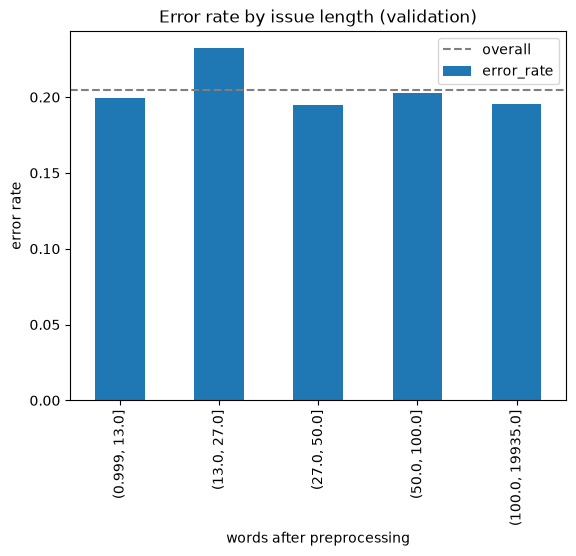

In [11]:
val["length_group"] = pd.qcut(val["n_words"], 5, duplicates="drop")

by_length = val.groupby("length_group", observed=True).agg(
    issues=("wrong", "size"),
    error_rate=("wrong", "mean"),
)
display(by_length.round(3))

by_length["error_rate"].plot(kind="bar", ylabel="error rate", xlabel="words after preprocessing",
                             title="Error rate by issue length (validation)")
plt.axhline(val["wrong"].mean(), color="gray", linestyle="--", label="overall")
plt.legend()
plt.show()

In [13]:
display(val.groupby(["length_group", "issue_label"], observed=True)["wrong"].mean().unstack().round(3))

issue_label,bug,enhancement,question
length_group,,,
"(0.999, 13.0]",0.301,0.119,0.513
"(13.0, 27.0]",0.257,0.177,0.457
"(27.0, 50.0]",0.178,0.175,0.374
"(50.0, 100.0]",0.133,0.245,0.422
"(100.0, 19935.0]",0.099,0.380,0.502


In [12]:
no_body = val["issue_body"].isna()
print(f"Empty body: {no_body.sum()} issues, error rate {val.loc[no_body, 'wrong'].mean():.3f}")

Empty body: 838 issues, error rate 0.185


**Answer:**
- **Overall, length barely matters:** every group is close to the mean error rate of 20.5%; only the 14–27 word group is slightly higher (23.2%). Issues with an empty body (838) are not harder either (18.5%); the title carries enough signal.
- **But the classes move in opposite directions, and cancel out in the total:**
  - **Bug:** errors fall steadily with length (30% → 10%). Long bug reports have steps to reproduce, stack traces and the bug template, which is a lot of evidence.
  - **Enhancement:** errors rise with length (12% → 38%). Long feature requests often contain logs, code or error messages and start to look like bug reports (Q2: 57748).
  - **Question:** U-shaped (51% → 37% → 50%). Short questions have too little text, long ones are mostly support requests with pasted errors, which look like bugs (Q3).
- Lesson: a flat total can hide opposite trends per class; always split by class before concluding "no effect".

## Findings

1. **Where the errors are:** bug ↔ enhancement mistakes are the most common in absolute numbers (627 bugs predicted as enhancement), but questions are hit hardest relative to their size: 45% are missed (26% → bug, 19% → enhancement), and about half of the predicted questions are wrong.
2. **Label noise is a large share of the errors:** 12 of 20 confident mistakes and 9 of 20 missed questions are label noise, i.e. the model was right and the label is wrong. Measured scores, especially for question, therefore underestimate the real quality, and a perfect model would still score well below 1.0 against these labels.
3. **Bug vs. question is partly undecidable from text:** support requests ("I get this error, please help") made up 6 of 20 missed questions. Whether they count as bug or question depends on the answer, not on the text.
4. **Genuine model errors are a minority and have clear causes:** boilerplate (Bugzilla migrations, issue templates), long logs drowning out the title, a `?` in a feature list, and question phrasing surrounded by technical vocabulary.
5. **What the model learned is mostly sensible, with two caveats:** template phrases are present but secondary, and `azure`/`az`/`msal` show repository shortcut learning. Coefficients of correlated features can't be read alone (`bug bug`, `qmark qmark` were counterweights).
6. **Error analysis found and fixed a preprocessing artifact:** `?` in stack traces was counted as a question mark. Counting only a `?` that ends a word removed it (macro-F1 0.723 → 0.724, within noise, kept for correctness).
7. **Length matters per class, not overall:** long issues are easier for bug and harder for enhancement; questions are hardest when very short or very long.